In [1]:
# # 05 - Collaborative filtering (item-kNN and SVD)
# Tune each method on a validation sample, compare them, then evaluate on the test set
# (model fitted on train + validation). Test ratings are never used to choose anything.

# %%
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from uniguide.config import get_path, load_config
from uniguide.data.stats import save_fig
from uniguide.evaluation.experiments import evaluate_models
from uniguide.evaluation.metrics import rating_errors
from uniguide.models.collaborative import CollaborativeRecommender

cfg = load_config()
SEED = cfg["seed"]
K_VALUES = tuple(cfg["evaluation"]["k_values"])
p = get_path("processed")
tables = get_path("results") / "tables"
tables.mkdir(parents=True, exist_ok=True)

train, val, test = (pd.read_parquet(p / f"{n}.parquet") for n in ["train", "val", "test"])
courses = pd.read_parquet(p / "courses.parquet")
cold_courses = set(json.loads((p / "cold_courses.json").read_text()))
courses_warm = courses[~courses["course_id"].isin(cold_courses)].reset_index(drop=True)
train_val = pd.concat([train, val], ignore_index=True)

# Validation sample (fixed seed) to keep the grids fast.
rng = np.random.default_rng(SEED)
val_users = val["user_id"].unique()
sample = rng.choice(val_users, size=min(3000, len(val_users)), replace=False)
val_sample = val[val["user_id"].isin(sample)]
n_items = courses_warm["course_id"].nunique()
print(f"{len(sample)} validation users, {n_items} courses")


3000 validation users, 380 courses


        param   ndcg@10
method                 
knn         5  0.061648
svd        10  0.130427

Best CF method on validation: svd
Copy into config.yaml -> model:
  cf_method: svd
  cf_n_neighbors: 5
  cf_n_components: 10


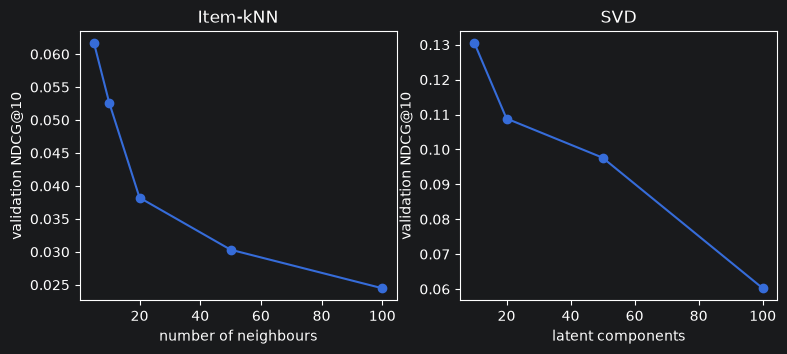

In [2]:
# ## 1. Tuning on validation (NDCG@10)

# %%
def ndcg10(results):
    return float(results.loc[results["metric"] == "ndcg", "value"].iloc[0])


rows = []
for n in [5, 10, 20, 50, 100]:
    model = CollaborativeRecommender(method="knn", n_neighbors=n, random_state=SEED).fit(train, courses_warm)
    r = evaluate_models({"cf_knn": model}, val_sample, (10,), experiment=f"knn_{n}")
    rows.append({"method": "knn", "param": n, "ndcg@10": ndcg10(r)})

for c in [c for c in [10, 20, 50, 100] if c < n_items]:
    model = CollaborativeRecommender(method="svd", n_components=c, random_state=SEED).fit(train, courses_warm)
    r = evaluate_models({"cf_svd": model}, val_sample, (10,), experiment=f"svd_{c}")
    rows.append({"method": "svd", "param": c, "ndcg@10": ndcg10(r)})

tuning = pd.DataFrame(rows)
tuning.to_csv(tables / "tuning_cf.csv", index=False)
tuning

# %%
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, (method, label) in zip(axes, [("knn", "number of neighbours"), ("svd", "latent components")]):
    t = tuning[tuning["method"] == method]
    ax.plot(t["param"], t["ndcg@10"], marker="o")
    ax.set(xlabel=label, ylabel="validation NDCG@10", title="Item-kNN" if method == "knn" else "SVD")
save_fig(fig, "cf_tuning")

best = tuning.loc[tuning.groupby("method")["ndcg@10"].idxmax()].set_index("method")
winner = best["ndcg@10"].idxmax()
print(best)
print(f"\nBest CF method on validation: {winner}")
print("Copy into config.yaml -> model:")
print(f"  cf_method: {winner}")
print(f"  cf_n_neighbors: {int(best.loc['knn', 'param'])}")
if "svd" in best.index:
    print(f"  cf_n_components: {int(best.loc['svd', 'param'])}")


In [3]:
# ## 2. Test evaluation (fit on train + validation)

# %%
final = {
    "cf_knn": CollaborativeRecommender(method="knn", n_neighbors=int(best.loc["knn", "param"]),
                                        random_state=SEED).fit(train_val, courses_warm),
}
if "svd" in best.index:
    final["cf_svd"] = CollaborativeRecommender(method="svd", n_components=int(best.loc["svd", "param"]),
                                               random_state=SEED).fit(train_val, courses_warm)

variants = evaluate_models(final, test, K_VALUES, experiment="main")
variants.to_csv(tables / "exp_cf_variants.csv", index=False)
variants.pivot_table(index="metric", columns=["method", "k"], values="value").round(4)

# %%
# Official CF result of the project: the winner on validation, saved per user under the name "collaborative".
per_user = evaluate_models({"collaborative": final[f"cf_{winner}"]}, test, K_VALUES, experiment="main",
                           seed=SEED, per_user=True)
per_user.to_csv(tables / "eval_collaborative.csv", index=False)
print(per_user.groupby(["k", "metric"])["value"].mean().unstack("metric").round(4))

#

metric  hit_rate    ndcg  precision  recall
k                                          
5         0.2053  0.1211     0.0445  0.1527
10        0.2822  0.1418     0.0317  0.2130


In [4]:
# ## 3. Rating prediction (optional MAE / RMSE)
# The baseline predicts the global mean training rating for every interaction.

# %%
errors = {name: rating_errors(model, test) for name, model in final.items()}
global_mean = train_val["rating"].mean()
errors["global_mean"] = {
    "mae": float((test["rating"] - global_mean).abs().mean()),
    "rmse": float(np.sqrt(((test["rating"] - global_mean) ** 2).mean())),
    "n_scored": len(test), "coverage": 1.0,
}
rating_table = pd.DataFrame(errors).T.round(4)
rating_table.to_csv(tables / "eval_rating_prediction.csv")
rating_table

,mae,rmse,n_scored,coverage
cf_knn,0.4853,0.8660,24629.0,1.0
cf_svd,4.3423,4.4484,24629.0,1.0
global_mean,0.5538,0.7921,24629.0,1.0
